In [10]:
import matplotlib.pyplot as plt
from PIL import Image
from brokenaxes import BrokenAxes
from intervaltree import Interval, IntervalTree
import numpy as np
import os
import random
import matplotlib.cm as cm

In [7]:
from PIL import Image


image = Image.open("change_to_black.png").convert("RGBA")
pixels = image.load()


for y in range(image.height):
    for x in range(image.width):
        r, g, b, a = pixels[x, y]
        if a == 0:
            continue  
        elif r == 255 and g == 255 and b == 255:
            continue  
        else:
           
            pixels[x, y] = (0, 0, 0, a)  

image.save("output_black_except_white.png")

In [2]:
def merge_intervals(intervals):
    """Merge overlapping x-axis intervals using IntervalTree."""
    tree = IntervalTree(Interval(start, end) for start, end in intervals)
    tree.merge_overlaps()  
    return sorted((iv.begin, iv.end) for iv in tree)  

In [3]:

def plot_dataset(dataset, dataset_idx, output_folder):
    num_blocks = len(dataset)
    cmap = cm.get_cmap('tab20', num_blocks)
    fig = plt.figure(figsize=(12, 4))
    for block_index, block in enumerate(dataset):
        x_min = min(int(item[0]) for item in block)
        x_max = max(int(item[1]) for item in block)
        #print(f"Dataset {dataset_idx}: xlim = ({x_min}, {x_max})")
        
        # plt.xlim(x_min, x_max)  # Set correct x-axis limits
        # plt.xlabel("X-Axis")  # Label x-axis
        # plt.ylabel("Y-Axis")  # Label y-axis
        # plt.grid(True, linestyle="--", alpha=0.5)  # Optional grid
        parameter = 1
        
        important_ranges = []
        important_ranges = [(start, end) for start, end, _ in block]
        merged_xlims = merge_intervals(important_ranges)
        print(merged_xlims)

    #     try:
    #         bax = BrokenAxes(xlims=merged_xlims, d=0.02)
    #     except AttributeError as e:
    #         print("BrokenAxes Error: Trying a workaround...")
    #         # bax = fig.add_axes([0.1, 0.1, 0.8, 0.8])  # Fallback to normal Axes

        distance = 0
        color = cmap(block_index)
        # total_line_count = 0
        for start, end, line_count in block:
            print(start,end,line_count)
            if merged_xlims and int(start) == merged_xlims[0][0]:
                # logging.info("start")
                # logging.info(start)
                distance = 0
                merged_xlims.pop(0)
            #     total_line_count = 0
            # total_line_count += line_count
            y_positions = [distance + parameter * (i + 1) for i in range(int(line_count))]
            print(y_positions)
            # random_color = np.random.rand(3,)
            for y in y_positions:
                plt.hlines(y, start, end, colors=color, linestyles='solid', linewidth=1)
            distance = y_positions[-1]
            
        print("compare:",distance,total_line_count)
    # plt.set_xlabel("X-Axis (Broken Scale)")
    # plt.set_ylabel("Y-Axis")
    
    # plt.show()


    buffer_path = f"{output_folder}/temp_plot_1_200_gaps_{dataset_idx}_blocks.png"
    plt.savefig(buffer_path, format='png', dpi=300, bbox_inches='tight')
    plt.close()


    # img = Image.open(buffer_path).convert('L')
    # binary_img = img.point(lambda x: 255 if x > 0 else 0, mode='1')


    # binary_img.save(f"{output_folder}/binary_plot_{dataset_idx}.png")
    # ##new code end

In [5]:
def collect_all_blocks_data(files,simulation_data_folder):
    bed_blocks = {}
    block_lines = []
    for file_name in files:
        try:
            file_path = os.path.join(simulation_data_folder, file_name)
            with open(file_path, "r") as file:
                bed_blocks[file_name] = []
                chrom_blocks = []
                line_block = []
                collecting = False
                for line in file:
                    line = line.strip()
                    if line == "":
                        collecting = False
                        if line_block:
                            bed_blocks[file_name].append(line_block)
                            line_block = []
                    elif line == "original bed lines:":
                        collecting = True
                    elif collecting:
                        columns = line.split('\t')
                        line_block.append([columns[0],columns[1],columns[2],columns[-1]])
        except Exception as e:
            print(f"Error opening file '{file_paths.get(file_name, 'UNKNOWN')}': {e}")
    return bed_blocks

In [5]:
def cluster_blocks_by_chrom(bed_blocks, files):
    group_all = {}
    for file_name in files:
        group = {}
        # group[chrom] = []
        group_all[file_name] = {}
        for block in bed_blocks[file_name]:
            chrom = block[0][0]
            if chrom not in group:
                group[chrom] = []
            group[chrom].append(block)
        group_all[file_name] = group
    return group_all

In [ ]:
def simulate_data_generation(original_data, blocks_number, start_point):
    random_block_id = random.randint(0, blocks_number - 1)
    original_min_start_point = min(int(line[1]) for line in original_data[random_block_id])
    original_max_end_point = max(int(line[2]) for line in original_data[random_block_id])
    move_units = original_min_start_point - start_point
    max_end_point = original_max_end_point - move_units
    block_data = []
    for line in original_data[random_block_id]:
        line_start = int(line[1])
        line_end = int(line[2])
        line_count = int(line[3])
        # print(line[1],line[2],line[3],min_start_point)
        count = 50 if line_count > 50 else line_count
        # print(line_start - min_start_point, line_end - min_start_point, count)
        block_data.append([line_start - move_units, line_end - move_units, count])
    
    return block_data, max_end_point


In [8]:
def generate_all_data(bed_blocks_group_by_chrom, files, blocks_number, smallest_gap, biggest_gap):
    number = 0
    dataset = []
    random_file = random.choice(files)
    random_chrom = random.choice(list(bed_blocks_group_by_chrom[random_file].keys()))
    start_point = 1 
    while number < blocks_number:
        random_file = random.choice(files)
        actual_blocks_number = len(bed_blocks_group_by_chrom[random_file][random_chrom])
        block_data, end_point = simulate_data_generation(bed_blocks_group_by_chrom[random_file][random_chrom], actual_blocks_number, start_point)
        dataset.append(block_data)
        start_point = end_point + random.randint(smallest_gap, biggest_gap)
        number += 1
    return dataset


In [10]:
simulation_data_folder = "simulation_data"
files = ["fully_symmetric_blocks.txt", "fully_overlapping_blocks.txt", 
             "partially_overlapping_blocks.txt", "singleton_blocks.txt", "other_situation_blocks.txt"]

bed_blocks = collect_all_blocks_data(files, simulation_data_folder)
# print(bed_blocks[files[0]])
bed_blocks_group_by_chrom = cluster_blocks_by_chrom(bed_blocks, files)
# print(bed_blocks_group_by_chrom)
# print(bed_blocks_group_by_chrom[files[0]])
#start simulating data
simulation_dataset = generate_all_data(bed_blocks_group_by_chrom, files, 15, 1, 200)
# print(simulation_dataset)


In [12]:
print(simulation_dataset)

[[[1, 31, 4], [20, 56, 10], [25, 56, 15], [25, 56, 1], [30, 56, 1], [31, 56, 1], [32, 56, 14], [33, 56, 13], [36, 56, 19]], [[114, 147, 7], [146, 170, 1]], [[255, 275, 40], [255, 280, 23], [255, 281, 15], [255, 284, 1], [311, 328, 1]], [[479, 509, 4], [498, 534, 10], [503, 534, 15], [503, 534, 1], [508, 534, 1], [509, 534, 1], [510, 534, 14], [511, 534, 13], [514, 534, 19]], [[700, 728, 9], [701, 718, 28], [719, 736, 27], [722, 753, 9], [725, 746, 22], [754, 771, 18], [754, 771, 1]], [[907, 926, 9]], [[937, 955, 1]], [[1075, 1096, 12]], [[1152, 1172, 16], [1262, 1290, 13]], [[1334, 1352, 15], [1334, 1365, 9], [1342, 1365, 14], [1375, 1407, 9], [1379, 1408, 12], [1380, 1408, 36], [1385, 1408, 9]], [[1590, 1609, 21]], [[1802, 1821, 1]], [[1941, 1966, 14]], [[2126, 2145, 1]], [[2161, 2178, 1], [2219, 2237, 44], [2220, 2237, 50]]]


In [19]:
plot_dataset(simulation_dataset, 15, "simulation_data")

/tmp/ipykernel_1127213/1263971057.py:4: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap('tab20', num_blocks)


[(1, 33), (98, 115)]
1 33 19
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
98 115 14
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
compare: 14 14
[(183, 204)]
183 204 1
[1]
compare: 1 1
[(312, 332)]
312 332 18
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]
compare: 18 18
[(360, 392), (457, 474)]
360 392 19
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
457 474 14
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
compare: 14 14
[(582, 613), (623, 656)]
582 600 15
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
582 613 9
[16, 17, 18, 19, 20, 21, 22, 23, 24]
590 613 14
[25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38]
623 655 9
[1, 2, 3, 4, 5, 6, 7, 8, 9]
627 656 12
[10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]
628 656 36
[22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57]
633 656 9
[58, 59, 60, 61, 62, 63, 64, 65, 66]
compa

In [8]:
import matplotlib.pyplot as plt
from PIL import Image
from brokenaxes import BrokenAxes
from intervaltree import Interval, IntervalTree
import numpy as np
import os
import random
import matplotlib.cm as cm
import argparse
import pandas as pd

def merge_intervals(intervals):
    """Merge overlapping x-axis intervals using IntervalTree."""
    tree = IntervalTree(Interval(start, end) for start, end in intervals)
    #merge overlapping intervals
    tree.merge_overlaps() 
    #return list (not tuple) 
    return sorted((iv.begin, iv.end) for iv in tree)

# function to plot each dataset
def plot_dataset(dataset, dataset_idx, output_folder):
    num_blocks = len(dataset)
    cmap = cm.get_cmap('tab20', num_blocks)
    fig, ax = plt.subplots(figsize=(12, 4))
    for block_index, block in enumerate(dataset):
        x_min = min(int(item[0]) for item in block)
        x_max = max(int(item[1]) for item in block)
        #print(f"Dataset {dataset_idx}: xlim = ({x_min}, {x_max})")
        parameter = 1

        important_ranges = []
        important_ranges = [(start, end) for start, end, _ in block]
        merged_xlims = merge_intervals(important_ranges)
        print(merged_xlims)

        distance = 0
        color = cmap(block_index)
        for start, end, line_count in block:
            print(start,end,line_count)
            if merged_xlims and int(start) == merged_xlims[0][0]:
                # logging.info("start")
                # logging.info(start)
                distance = 0
                merged_xlims.pop(0)
            y_positions = [distance + parameter * (i + 1) for i in range(int(line_count))]
            print(y_positions)
            # random_color = np.random.rand(3,)
            for y in y_positions:
                plt.hlines(y, start, end, colors=color, linestyles='solid', linewidth=1)
            distance = y_positions[-1]
            

    ax.set_xlabel("Genome Position")
    ax.set_ylabel("Coverage")    
    # plt.show()

    #save the plot to a buffer as a grayscale image
    buffer_path = f"{output_folder}/simulation_1_200_gaps_{dataset_idx}_blocks.png"
    plt.savefig(buffer_path, format='png', dpi=300, bbox_inches='tight')
    plt.close()

def collect_all_blocks_data(simulation_data_folder, files):
    bed_blocks = {}
    block_lines = []
    print(files)
    for file_name in files:
        try:
            file_path = os.path.join(simulation_data_folder, file_name)
            with open(file_path, "r") as file:
                bed_blocks[file_name] = []
                chrom_blocks = []
                line_block = []
                collecting = False
                for line in file:
                    line = line.strip()
                    if line == "":
                        collecting = False
                        if line_block:
                            bed_blocks[file_name].append(line_block)
                            line_block = []
                    elif line == "original bed lines:":
                        collecting = True
                    elif collecting:
                        columns = line.split('\t')
                        line_block.append([columns[0],columns[1],columns[2],columns[3], columns[4], columns[5], columns[6]])
        except Exception as e:
            print(f"Error opening file '{file_paths.get(file_name, 'UNKNOWN')}': {e}")
    return bed_blocks

def cluster_blocks_by_chrom(bed_blocks, files):
    group_all = {}
    for file_name in files:
        group = {}
        # group[chrom] = []
        group_all[file_name] = {}
        for block in bed_blocks[file_name]:
            chrom = block[0][0]
            if chrom not in group:
                group[chrom] = []
            group[chrom].append(block)
        group_all[file_name] = group
    return group_all

def simulate_data_generation(original_data, blocks_number, start_point):
    random_block_id = random.randint(0, blocks_number - 1)
    original_min_start_point = min(int(line[1]) for line in original_data[random_block_id])
    original_max_end_point = max(int(line[2]) for line in original_data[random_block_id])
    move_units = original_min_start_point - start_point
    max_end_point = original_max_end_point - move_units
    whole_block_data = []
    block_data = []
    for line in original_data[random_block_id]:
        line_start = int(line[1])
        line_end = int(line[2])
        line_count = int(line[6])
        # print(line[1],line[2],line[3],min_start_point)
        count = 50 if line_count > 50 else line_count
        # print(line_start - min_start_point, line_end - min_start_point, count)
        whole_block_data.append([line[0], line_start - move_units, line_end - move_units, line[3], line[4], line[5], count])
        block_data.append([line_start - move_units, line_end - move_units, count])
    
    return block_data, whole_block_data, max_end_point

def generate_all_data(bed_blocks_group_by_chrom, files, blocks_number, smallest_gap, biggest_gap):
    number = 0
    dataset = []
    whole_dataset = {}
    random_file = random.choice(files)
    random_chrom = random.choice(list(bed_blocks_group_by_chrom[random_file].keys()))
    start_point = 1 
    while number < blocks_number:
        random_file = random.choice(files)
        actual_blocks_number = len(bed_blocks_group_by_chrom[random_file][random_chrom])
        block_data, whole_block_data, end_point = simulate_data_generation(bed_blocks_group_by_chrom[random_file][random_chrom], actual_blocks_number, start_point)
        dataset.append(block_data)
        whole_dataset[number] = whole_block_data
        print("whole_block_data", whole_block_data)
        start_point = end_point + random.randint(smallest_gap, biggest_gap)
        number += 1
    return dataset, whole_dataset


def simulate_blocks(input_files, number_of_blocks, block_gap_min_threshold, block_gap_max_threshold, output_folder):
    # simulation_data_folder = "simulation_data"
    # files = ["fully_symmetric_blocks.txt", "fully_overlapping_blocks.txt", 
    #             "partially_overlapping_blocks.txt", "singleton_blocks.txt", "other_situation_blocks.txt"]
    #prepare all the data
    input_files_list = input_files.split()
    if not input_files_list:
        raise ValueError(f"input files' paths: '{input_files}' is wrong")
    files = []
    for file_path in input_files_list:
        files.append(os.path.basename(file_path))
    simulation_data_folder = os.path.dirname(input_files_list[0])

    bed_blocks = collect_all_blocks_data(simulation_data_folder, files)
    # print(bed_blocks[files[0]])
    bed_blocks_group_by_chrom = cluster_blocks_by_chrom(bed_blocks, files)
    # print(bed_blocks_group_by_chrom)
    # print(bed_blocks_group_by_chrom[files[0]])
    #start simulating data
    simulation_dataset,whole_dataset = generate_all_data(bed_blocks_group_by_chrom, files, int(number_of_blocks), int(block_gap_min_threshold), int(block_gap_max_threshold))
    print("simulation_dataset start:")
    print(simulation_dataset)
    print("simulation_dataset end.")
    print("whole_dataset start:")
    print(whole_dataset)
    print("whole_dataset end.")

    df = pd.DataFrame(data, columns=['chrome', 'start', 'end','sequence','id','same_ids','same_seq_count'])
    df.sort_values(by=['chrome', 'start', 'end'], ascending=[True, True, True], inplace=True)
    sorted_data = []
    sorted_data = df.values.tolist()

    # write data to the bed file
    with open(bed_file_path, "w") as file:
        for line in sorted_data:
            file.write("\t".join(map(str, line)) + "\n")
    ##run additonal step
    
    ##get table and compare with
    plot_dataset(simulation_dataset, 15, output_folder)

In [9]:
simulation_data_folder = "simulation_data"
files = ["fully_symmetric_blocks.txt", "fully_overlapping_blocks.txt", 
             "partially_overlapping_blocks.txt", "singleton_blocks.txt", "other_situation_blocks.txt"]
simulate_blocks("simulation_data/fully_symmetric_blocks.txt simulation_data/fully_overlapping_blocks.txt simulation_data/partially_overlapping_blocks.txt simulation_data/singleton_blocks.txt simulation_data/other_situation_blocks.txt", 15, 1, 200, simulation_data_folder)


['fully_symmetric_blocks.txt', 'fully_overlapping_blocks.txt', 'partially_overlapping_blocks.txt', 'singleton_blocks.txt', 'other_situation_blocks.txt']
whole_block_data [['NZ_LR134354.1', 1, 21, 'CGGACCTTTGACGGTGATATA', '71950', '71950|162032|274665|292889|405841|431822|439283|474026|474385|485967|581929|599807|701314', 13]]
whole_block_data [['NZ_LR134354.1', 62, 79, 'TGTGGTCGCGGTGATCGA', '22486', '22486|113583|167357|180682|212845|251159|286464|298090|332875|413618|441589|494017|566955|577228|624901|776951|779759|779776', 18]]
whole_block_data [['NZ_LR134354.1', 182, 199, 'TGAACAGGTTGTCGTTCT', '92616', '92616|136890|206662|239657|314043|403826|452068|467636|473922|494445|506190|507038|507112|509306|567131|685264|687413|718559|780668', 19]]
whole_block_data [['NZ_LR134354.1', 319, 336, 'CATGGTCGAGGGCGTGCG', '206435', '206435', 1]]
whole_block_data [['NZ_LR134354.1', 442, 460, 'CCTGCAGAAGGTGATCGTA', '21724', '21724|108197|130819|153921|196798|201156|209405|221667|319018|319255|340437|

NameError: name 'pd' is not defined

In [1]:
# function to plot each dataset
def plot_dataset(block, dataset_idx, output_folder):

    fig = plt.figure(figsize=(12, 4))
    x_min = min(int(item[0]) for item in block)
    x_max = max(int(item[1]) for item in block)
    parameter = 0.05
    # Step 1: Create unique x-limits based on dataset
    important_ranges = []
    important_ranges = [(start, end) for start, end, _ in block]
    merged_xlims = merge_intervals(important_ranges)
    print(merged_xlims)
    distance = 0
    for start, end, line_count in block:
        if merged_xlims and int(start) == merged_xlims[0][0]:
            # logging.info("start")
            # logging.info(start)
            distance = 0
            merged_xlims.pop(0)
        y_positions = [distance + parameter * (i + 1) for i in range(int(line_count))]
        # print(y_positions)
        # random_color = np.random.rand(3,)
        for y in y_positions:
            plt.hlines(y, start, end, colors="purple", linestyles='solid', linewidth=1)
        distance = y_positions[-1]
    
    # plt.show()

    #save the plot to a buffer as a grayscale image
    buffer_path = f"{output_folder}/temp_plot_1_200_{dataset_idx}.png"
    plt.savefig(buffer_path, format='png', dpi=300, bbox_inches='tight')
    plt.close()

[(4, 21), (62, 80), (100, 114), (230, 254), (282, 299), (318, 341), (345, 376), (381, 430), (500, 557), (615, 635), (643, 660), (675, 694), (761, 779), (866, 904), (923, 951), (1010, 1046)]


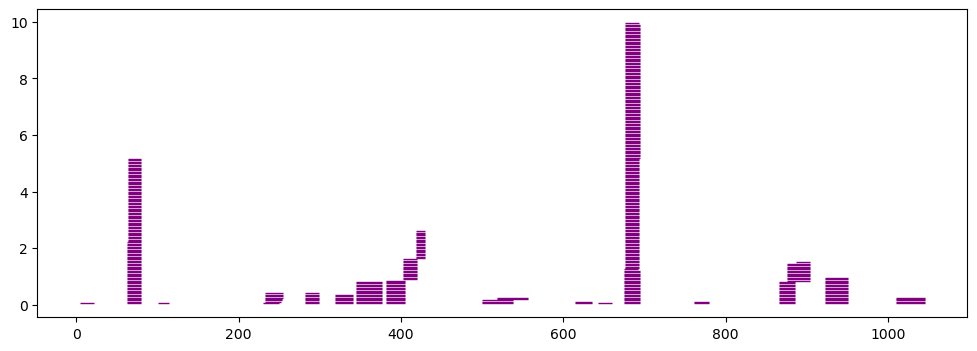

In [77]:
dataset = [ [4,21,1],[62,80,44],[63,80,59],[100,114,1], 
            [230,249,1],[232,252,1],[232,253,2],[232,254,4],[282,299,8],[318,341,7],
            [345,376,16],[381,405,17],[402,420,15],[418,430,20],
            [500,538,3],[518,557,2],[615,635,2],[643,660,1],
            [675,694,24],[675,692,1],[676,693,78],[676,694,95],[676,693,1],[761,779,2],
            [866,886,16],[876,904,13],[887,904,1],[923,951,19],[1010,1046,5]
         ]
plot_dataset(dataset, 0, "simulation_data")